# 3.4 Support vector machines

Margins, soft margins, and the kernel trick -- a linear SVM baseline, then
an RBF kernel to see whether a non-linear boundary helps, on the same
churn target/features/split.

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

Every classification notebook predicts the **same target, from the same
features, on the same train/test split** -- so the confusion matrix/ROC/AUC
numbers below are directly comparable to the other technique notebooks in
this folder.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split
from plotting import plot_confusion, plot_roc, plot_lift

features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
X = df[features]
y = df["churned"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape, " churn rate (train/test):", round(ytr.mean(),3), round(yte.mean(),3))

train: (210, 7)  test: (90, 7)  churn rate (train/test): 0.338 0.344


## Basic setup and soft margins (linear kernel)

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score

scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

for C in [0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel="linear", C=C, probability=True, random_state=0).fit(Xtr_s, ytr)
    auc = roc_auc_score(yte, m.predict_proba(Xte_s)[:, 1])
    print(f"C={C:<6}  n_support_vectors={m.n_support_.sum():<4}  test AUC={auc:.3f}")

C=0.01    n_support_vectors=144   test AUC=0.739
C=0.1     n_support_vectors=141   test AUC=0.747
C=1       n_support_vectors=138   test AUC=0.741
C=10      n_support_vectors=136   test AUC=0.739


C=100     n_support_vectors=136   test AUC=0.739


`C` controls how soft the margin is: a small `C` allows more margin
violations (wider margin, more bias/less variance), a large `C` pushes
toward a harder margin that fits the training data more tightly (less
bias/more variance) -- the "what if we can't find perfect separation"
trade-off.

## The kernel trick: does a non-linear boundary help?

In [4]:
linear_clf = SVC(kernel="linear", C=1, probability=True, random_state=0).fit(Xtr_s, ytr)
rbf_clf = SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=0).fit(Xtr_s, ytr)

print("Linear kernel AUC:", round(roc_auc_score(yte, linear_clf.predict_proba(Xte_s)[:, 1]), 3))
print("RBF kernel AUC   :", round(roc_auc_score(yte, rbf_clf.predict_proba(Xte_s)[:, 1]), 3))

Linear kernel AUC: 0.741
RBF kernel AUC   : 0.659


In [5]:
clf = rbf_clf

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2684: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


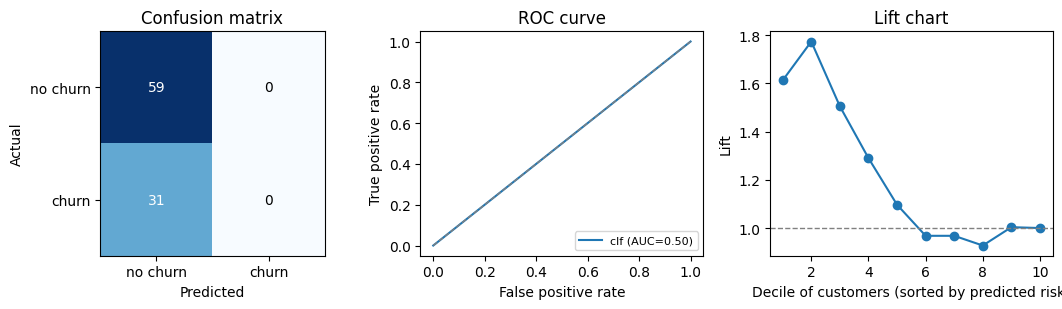

AUC: 0.5


In [6]:
y_pred = clf.predict(Xte)
y_score = clf.predict_proba(Xte)[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
plot_confusion(yte, y_pred, ax=axes[0])
auc_val = plot_roc(yte, y_score, ax=axes[1], label="clf")
plot_lift(yte, y_score, ax=axes[2])
plt.tight_layout(); plt.show()
print("AUC:", round(auc_val, 3))

**Wrap-up**: the RBF kernel implicitly projects the data into a
higher-dimensional space where a linear separator can capture a curved
boundary in the original feature space, without ever computing that
higher-dimensional mapping explicitly -- that's the "trick".